# 0. Atom, mass and charge balances as linear constraints

Flow meters and analysers are noisy, so a set of measured flows around a reactor rarely satisfies the atom balances exactly, and a model fitted to such data inherits the error. This lecture writes the balances of the elements, of total mass and of charge as one linear system, $\mathbf{C}\mathbf{w} = \mathbf{d}$. The null space of $\mathbf{C}$ then gives the independent reactions, and every composition that satisfies the balances is the feed plus a combination of them.

## Learning objectives

1. Assemble the matrix of atom counts and charges for a gas-phase synthesis and for an aqueous electrolyte.
2. Show, and check numerically, that the balance of total mass follows from the balances of the elements.
3. Compute the null space of the balance matrix by SVD and write every admissible outlet composition in terms of extents of reaction.
4. Measure by how much noisy measurements violate the balances of atoms and mass.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
In any non-nuclear chemical process involving $S$ chemical species and $E$ conserved elements (e.g., $\mathrm{C, H, O, N}$) plus ionic charge $z_j$, every physically admissible molar flow or yield vector $\mathbf{w} \in \mathbb{R}^S$ ($\mathrm{mol/s}$) must satisfy the exact linear conservation system:
$$\mathbf{C}\mathbf{w} = \mathbf{d}, \qquad \mathbf{C} \in \mathbb{R}^{E \times S}, \quad \mathbf{d} = \mathbf{C}\mathbf{w}_{\mathrm{feed}} \in \mathbb{R}^E \tag{1.1}$$
where $C_{e,j}$ is the number of atoms of element $e$ (or ionic charge $z_j$) in one molecule of species $j$, and $d_e$ is the conserved elemental feed rate ($\mathrm{mol/s}$). Because the molar mass vector $\mathbf{m} \in \mathbb{R}^S$ ($\mathrm{g/mol}$) is a linear combination of the rows of $\mathbf{C}$ weighted by the atomic weights $\mathbf{a} \in \mathbb{R}^E$ ($\mathbf{m}^\top = \mathbf{a}^\top \mathbf{C}$), total mass closure is automatically guaranteed whenever Eq. (1.1) holds:
$$\mathbf{m}^\top \mathbf{w} = \mathbf{a}^\top (\mathbf{C}\mathbf{w}) = \mathbf{a}^\top \mathbf{d} = m_{\mathrm{feed}} \tag{1.2}$$
By the **rank-nullity theorem**, the set of all conserved reactor states forms an affine manifold of dimension $R = S - \mathrm{rank}(\mathbf{C})$ parameterized by the independent reaction extent vector $\boldsymbol{\xi} \in \mathbb{R}^R$:
$$\mathbf{w}(\boldsymbol{\xi}) = \mathbf{w}_{\mathrm{feed}} + \boldsymbol{\nu}^\top \boldsymbol{\xi}, \qquad \mathbf{C}\boldsymbol{\nu}^\top = \mathbf{0}_{E \times R} \tag{1.3}$$
where the $R$ rows of the stoichiometric matrix $\boldsymbol{\nu} \in \mathbb{R}^{R \times S}$ span the right nullspace $\mathcal{N}(\mathbf{C})$.

In [2]:
heading("Demonstration 1: Atomic Formula Matrix & Mass-Balance Linear Dependence")
# Species order: [CH3OH, CO, H2O, CO2, H2] for methanol synthesis (Feed: 1 mol CO2 + 3 mol H2)
species = ["CH3OH", "CO", "H2O", "CO2", "H2"]
C_atom = np.array([
    [1.0, 1.0, 0.0, 1.0, 0.0],  # Carbon (C) atoms per molecule
    [4.0, 0.0, 2.0, 0.0, 2.0],  # Hydrogen (H) atoms per molecule
    [1.0, 1.0, 1.0, 2.0, 0.0],  # Oxygen (O) atoms per molecule
])
atomic_masses = np.array([12.011, 1.008, 15.999])  # [C, H, O] in g/mol
molar_masses = atomic_masses @ C_atom
w_feed = np.array([0.0, 0.0, 0.0, 1.0, 3.0])
d_atom = C_atom @ w_feed
feed_mass = float(molar_masses @ w_feed)

print(f"{'Species':>8s} | {'C':>3s} {'H':>3s} {'O':>3s} | {'Molar Mass [g/mol]':>18s} | {'Feed [mol]':>10s}")
print("-" * 54)
for sp, col, mw, wf in zip(species, C_atom.T, molar_masses, w_feed):
    print(f"{sp:>8s} | {int(col[0]):3d} {int(col[1]):3d} {int(col[2]):3d} | {mw:18.3f} | {wf:10.3f}")

C_augmented_mass = np.vstack([C_atom, molar_masses])
assert np.linalg.matrix_rank(C_atom) == 3
assert np.linalg.matrix_rank(C_augmented_mass) == 3, "Mass row m^T = a^T C must not increase rank!"
print(f"\nElemental feed d = {d_atom} mol | Total feed mass = {feed_mass:.3f} g | rank(C) = {np.linalg.matrix_rank(C_atom)}")


Demonstration 1: Atomic Formula Matrix & Mass-Balance Linear Dependence
 Species |   C   H   O | Molar Mass [g/mol] | Feed [mol]
------------------------------------------------------
   CH3OH |   1   4   1 |             32.042 |      0.000
      CO |   1   0   1 |             28.010 |      0.000
     H2O |   0   2   1 |             18.015 |      0.000
     CO2 |   1   0   2 |             44.009 |      1.000
      H2 |   0   2   0 |              2.016 |      3.000

Elemental feed d = [1. 6. 2.] mol | Total feed mass = 50.057 g | rank(C) = 3


**What Demonstration 1 shows.** Every species molar mass is an exact linear combination of the $\mathrm{C, H, O}$ rows ($\mathbf{m}^\top = \mathbf{a}^\top \mathbf{C}$), so appending a total mass-balance row leaves $\mathrm{rank}(\mathbf{C}) = 3$ unchanged.

---

## 2. Numerical walkthrough
To construct the stoichiometric reaction subspace for the $S = 5$ species and $\mathrm{rank}(\mathbf{C}) = 3$ elemental invariants, we note that $R = S - \mathrm{rank}(\mathbf{C}) = 5 - 3 = 2$ independent reactions exist:
1. **Methanol synthesis ($\xi_1$):** $\mathrm{CO_2 + 3\,H_2 \rightleftharpoons CH_3OH + H_2O}$, $\boldsymbol{\nu}_1 = [+1, 0, +1, -1, -3]$.
2. **Reverse water–gas shift ($\xi_2$):** $\mathrm{CO_2 + H_2 \rightleftharpoons CO + H_2O}$, $\boldsymbol{\nu}_2 = [0, +1, +1, -1, -1]$.

We verify below that $\mathbf{C}\boldsymbol{\nu}^\top = \mathbf{0}$ and that the right singular vectors of $\mathbf{C}$ corresponding to zero singular values span the exact same 2-D reaction subspace.

In [3]:
heading("Demonstration 2: Stoichiometric Reaction Matrix & SVD Nullspace Projection")
nu = np.array([
    [1.0, 0.0, 1.0, -1.0, -3.0],  # Rxn 1: CO2 + 3 H2 <-> CH3OH + H2O
    [0.0, 1.0, 1.0, -1.0, -1.0],  # Rxn 2: CO2 + H2   <-> CO    + H2O
])
U_c, s_c, Vt_c = np.linalg.svd(C_atom, full_matrices=True)
N_svd = Vt_c[3:, :].T  # Orthonormal basis for the 2-D nullspace N(C)
P_null = N_svd @ N_svd.T

# Project physical reaction vectors nu onto the SVD nullspace basis:
nu_projected = (P_null @ nu.T).T
print("Singular values of C_atom:", np.round(s_c, 6))
print("Stoichiometric nullspace residual ||C_atom @ nu^T||_max:", float(np.max(np.abs(C_atom @ nu.T))))
print("Subspace projection discrepancy ||nu - P_null nu||_max  :", float(np.max(np.abs(nu - nu_projected))))
assert np.allclose(C_atom @ nu.T, 0.0, atol=1e-15)
assert np.allclose(nu, nu_projected, atol=1e-14)


Demonstration 2: Stoichiometric Reaction Matrix & SVD Nullspace Projection
Singular values of C_atom: [5.193314 2.550512 0.724139]
Stoichiometric nullspace residual ||C_atom @ nu^T||_max: 0.0
Subspace projection discrepancy ||nu - P_null nu||_max  : 4.440892098500626e-16


**What Demonstration 2 shows.** Both chemical reactions lie identically in the 2-D nullspace $\mathcal{N}(\mathbf{C})$ spanned by the trailing singular vectors of $\mathbf{C}_{\mathrm{atom}}$.

---

## 3. Worked case study
Let us compare true stoichiometric reactor effluents $\mathbf{w}(\boldsymbol{\xi}) = \mathbf{w}_{\mathrm{feed}} + \boldsymbol{\nu}^\top \boldsymbol{\xi}$ against raw, unconstrained gas-chromatograph (GC) measurements $\mathbf{w}_{\mathrm{GC}} = \mathbf{w}_{\mathrm{true}} + \boldsymbol{\varepsilon}$ at three operating points.

In [4]:
heading("Demonstration 3: Stoichiometric Reactor Benchmark vs. Raw Unconstrained GC Sensor")
xi_grid = np.array([[0.24, 0.08], [0.35, 0.12], [0.10, 0.20]])
for idx, xi in enumerate(xi_grid, start=1):
    w_state = w_feed + nu.T @ xi
    atom_res = float(np.max(np.abs(C_atom @ w_state - d_atom)))
    mass_now = float(molar_masses @ w_state)
    print(f"Operating Point {idx} (xi={xi}) | Effluent w={np.round(w_state, 3)} | Mass={mass_now:.3f} g | Atom err={atom_res:.1e}")
    assert np.allclose(C_atom @ w_state, d_atom, atol=1e-14)
    assert np.isclose(mass_now, feed_mass, rtol=1e-14)

rng = np.random.default_rng(42)
w_true = w_feed + nu.T @ np.array([0.24, 0.08])
w_noisy_gc = w_true + rng.normal(0.0, 0.05, size=5)
atom_violation = C_atom @ w_noisy_gc - d_atom
mass_violation = float(molar_masses @ w_noisy_gc) - feed_mass
print(f"\nNoisy raw GC elemental imbalance [dC, dH, dO]: {np.round(atom_violation, 4)} mol")
print(f"Noisy raw GC phantom mass created            : {mass_violation:+.4f} g (out of {feed_mass:.3f} g)")
assert abs(mass_violation) > 0.1


Demonstration 3: Stoichiometric Reactor Benchmark vs. Raw Unconstrained GC Sensor
Operating Point 1 (xi=[0.24 0.08]) | Effluent w=[0.24 0.08 0.32 0.68 2.2 ] | Mass=50.057 g | Atom err=1.1e-16
Operating Point 2 (xi=[0.35 0.12]) | Effluent w=[0.35 0.12 0.47 0.53 1.83] | Mass=50.057 g | Atom err=0.0e+00
Operating Point 3 (xi=[0.1 0.2]) | Effluent w=[0.1 0.2 0.3 0.7 2.5] | Mass=50.057 g | Atom err=1.1e-16

Noisy raw GC elemental imbalance [dC, dH, dO]: [ 0.0103 -0.0591  0.0948] mol
Noisy raw GC phantom mass created            : +1.5807 g (out of 50.057 g)


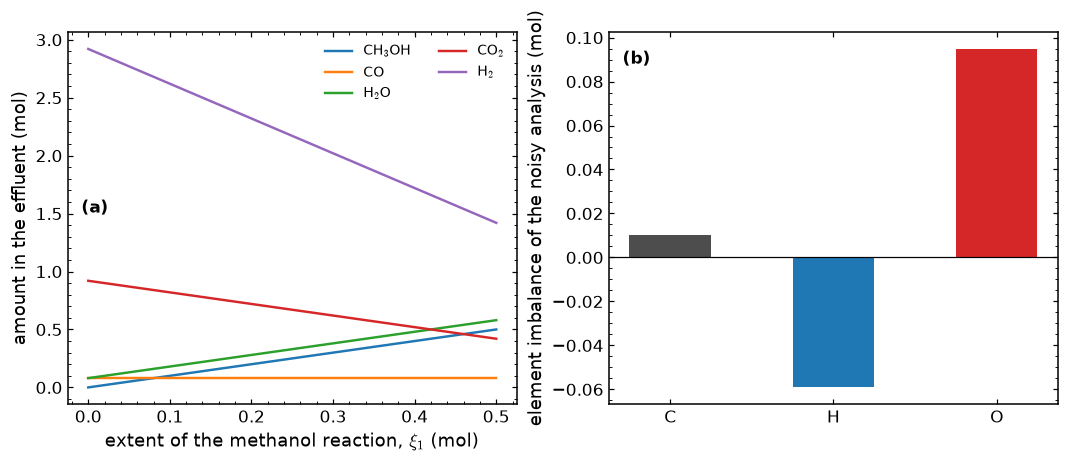

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
species = [r"CH$_3$OH", "CO", r"H$_2$O", r"CO$_2$", r"H$_2$"]
xi1_line = np.linspace(0.0, 0.5, 51)
W_line = w_feed[None, :] + xi1_line[:, None] * nu[0][None, :] + 0.08 * nu[1][None, :]
for j, name in enumerate(species):
    ax1.plot(xi1_line, W_line[:, j], label=name)
ax1.set_xlabel(r"extent of the methanol reaction, $\xi_1$ (mol)"); ax1.set_ylabel("amount in the effluent (mol)")
ax1.legend(ncol=2, fontsize=9, loc="upper right"); panel_label(ax1, "(a)", x=0.03, y=0.55)
ax2.bar(["C", "H", "O"], atom_violation, color=["0.3", "C0", "C3"], width=0.5)
ax2.axhline(0.0, color="k", lw=0.8); ax2.tick_params(axis="x", which="minor", bottom=False, top=False)
ax2.set_ylabel("element imbalance of the noisy analysis (mol)"); panel_label(ax2, "(b)")
plt.show()

**Figure 0.1.** (a) The effluent of the reactor as the extent of the methanol reaction varies, with the extent of the second reaction fixed at 0.08 mol: every composition on these lines conserves carbon, hydrogen and oxygen. (b) A synthetic analysis with noise of 0.05 mol on each species does not lie on them: the imbalance in each element.

**What Demonstration 3 shows.** The three operating points computed from reaction extents conserve every element to rounding error. A synthetic analysis with Gaussian noise of $0.05\;\mathrm{mol}$ on each species does not: it is out of balance by $0.01$, $-0.06$ and $0.09\;\mathrm{mol}$ in carbon, hydrogen and oxygen, and reports $1.58\;\mathrm{g}$ more mass than the $50.057\;\mathrm{g}$ that were fed.

---

## 4. What if: sensitivity to the parameters
What happens to the worst-case phantom mass violation $|\mathbf{m}^\top \mathbf{w}_{\mathrm{GC}} - m_{\mathrm{feed}}|$ as GC analyzer noise $\sigma_{\mathrm{GC}}$ increases from $0.001\;\mathrm{mol}$ to $0.10\;\mathrm{mol}$? And how does orthogonal projection onto the affine conservation plane remove this error?

In [6]:
heading("Demonstration 4: Analyzer Noise Sweep & Affine Conservation Projection")
C_pinv = C_atom.T @ np.linalg.inv(C_atom @ C_atom.T)
unit_noise = rng.normal(0.0, 1.0, size=5)
print(f"{'Noise sigma [mol]':>18s} | {'Raw Atom Err [mol]':>18s} | {'Raw Mass Err [g]':>16s} | {'Projected Atom Err':>18s}")
print("-" * 78)
for sig in [0.001, 0.01, 0.05, 0.10]:
    w_raw = w_true + sig * unit_noise
    w_proj = w_raw - C_pinv @ (C_atom @ w_raw - d_atom)
    raw_a = float(np.max(np.abs(C_atom @ w_raw - d_atom)))
    raw_m = abs(float(molar_masses @ w_raw) - feed_mass)
    prj_a = float(np.max(np.abs(C_atom @ w_proj - d_atom)))
    print(f"{sig:18.3f} | {raw_a:18.5f} | {raw_m:16.5f} | {prj_a:18.2e}")
    assert prj_a < 1e-14


Demonstration 4: Analyzer Noise Sweep & Affine Conservation Projection
 Noise sigma [mol] | Raw Atom Err [mol] | Raw Mass Err [g] | Projected Atom Err
------------------------------------------------------------------------------
             0.001 |            0.00755 |          0.04630 |           0.00e+00
             0.010 |            0.07547 |          0.46300 |           0.00e+00
             0.050 |            0.37736 |          2.31499 |           2.22e-16
             0.100 |            0.75473 |          4.62999 |           1.11e-16


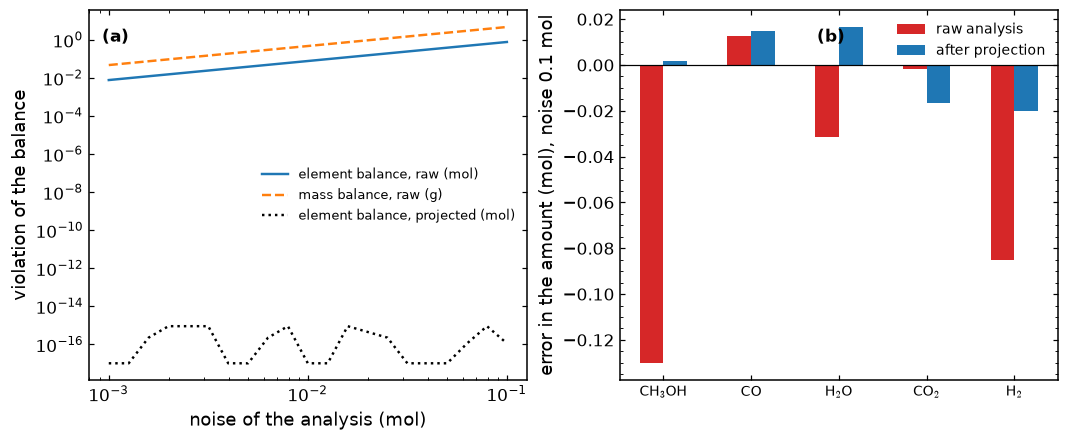

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
sig_line = np.logspace(-3, -1, 21); raw_a, raw_m, prj_a = [], [], []
for sig in sig_line:
    w_raw = w_true + sig * unit_noise
    w_proj = w_raw - C_pinv @ (C_atom @ w_raw - d_atom)
    raw_a.append(np.max(np.abs(C_atom @ w_raw - d_atom))); raw_m.append(abs(molar_masses @ w_raw - feed_mass))
    prj_a.append(max(np.max(np.abs(C_atom @ w_proj - d_atom)), 1e-17))
ax1.loglog(sig_line, raw_a, label="element balance, raw (mol)"); ax1.loglog(sig_line, raw_m, "--", label="mass balance, raw (g)")
ax1.loglog(sig_line, prj_a, ":", color="k", label="element balance, projected (mol)")
ax1.set_xlabel("noise of the analysis (mol)"); ax1.set_ylabel("violation of the balance")
ax1.legend(fontsize=8.5, loc="center right"); panel_label(ax1, "(a)")
pos = np.arange(5); width = 0.27
ax2.bar(pos - width, w_raw - w_true, width, color="C3", label="raw analysis")
ax2.bar(pos, w_proj - w_true, width, color="C0", label="after projection")
ax2.axhline(0.0, color="k", lw=0.8); ax2.set_xticks(pos - width / 2)
ax2.set_xticklabels([r"CH$_3$OH", "CO", r"H$_2$O", r"CO$_2$", r"H$_2$"], fontsize=9); ax2.tick_params(axis="x", which="minor", bottom=False, top=False)
ax2.set_ylabel("error in the amount (mol), noise 0.1 mol"); ax2.legend(fontsize=9); panel_label(ax2, "(b)", x=0.45)
plt.show()

**Figure 0.2.** (a) The violation of the balances by the raw analysis grows in proportion to its noise; after the projection it is at rounding level. (b) The error in each species before and after the projection, at the largest noise. The projection removes the part of the error that breaks the balances and leaves the part that looks like a change of reaction extent.

**What Demonstration 4 shows.** The violations of the element and mass balances by the raw analysis grow in proportion to the noise. The projection onto $\mathbf{C}\mathbf{w} = \mathbf{d}$ restores the balances to rounding error at every noise level. The projection makes the analysis consistent; it does not remove the noise in the directions that conserve atoms, which are the reaction extents.

---

## Inside the algorithm
Below we verify side-by-side that a pure-NumPy minimum-norm affine projection $\hat{\mathbf{w}} = \mathbf{w}_{\mathrm{raw}} - \mathbf{C}^\top(\mathbf{C}\mathbf{C}^\top)^{-1}(\mathbf{C}\mathbf{w}_{\mathrm{raw}} - \mathbf{d})$ agrees digit-for-digit with `linear_physics.equality_constrained_lstsq(np.eye(5), w_raw, C_atom, d_atom, lam=0.0)`.

In [8]:
heading("Inside the Algorithm: By-Hand Affine Projection vs. the Library")
w_by_hand = w_noisy_gc - C_atom.T @ np.linalg.solve(C_atom @ C_atom.T, C_atom @ w_noisy_gc - d_atom)
w_library = linear_physics.equality_constrained_lstsq(np.eye(5), w_noisy_gc, C_atom, d_atom, lam=0.0)["w"]
diff_norm = float(np.max(np.abs(w_by_hand - w_library)))
print("by hand (pure NumPy):", np.round(w_by_hand, 6))
print("library (engml_2_applied)     :", np.round(w_library, 6))
print(f"Max digit-for-digit discrepancy: {diff_norm:.2e}")
assert diff_norm < 1e-13


Inside the Algorithm: By-Hand Affine Projection vs. the Library
by hand (pure NumPy): [0.284057 0.033941 0.317998 0.682002 2.113889]
library (engml_2_applied)     : [0.284057 0.033941 0.317998 0.682002 2.113889]
Max digit-for-digit discrepancy: 2.78e-16


## Exercises

1. **Verify a result.** Construct the $4 \times 6$ elemental + charge conservation matrix $\mathbf{C}_{\mathrm{aq}}$ (rows: $\mathrm{C, H, O}$, and ionic charge $z$) for the 6-species aqueous carbonate system $[\mathrm{CO_2(aq)}, \mathrm{H_2O}, \mathrm{H^+}, \mathrm{OH^-}, \mathrm{HCO_3^-}, \mathrm{CO_3^{2-}}]$. Verify that all three equilibrium reactions ($\mathrm{CO_2 + H_2O \rightleftharpoons H^+ + HCO_3^-}$, $\mathrm{HCO_3^- \rightleftharpoons H^+ + CO_3^{2-}}$, and $\mathrm{H_2O \rightleftharpoons H^+ + OH^-}$) lie identically in $\mathcal{N}(\mathbf{C}_{\mathrm{aq}})$ and prove that $\mathrm{rank}(\mathbf{C}_{\mathrm{aq}}) = 3$ due to the oxidation-state identity $z = n_{\mathrm{H}} - 2n_{\mathrm{C}} - n_{\mathrm{O}}$.
2. **Find how it fails.** Suppose an uncalibrated pH/ion-selective electrode array reports the perturbed aqueous concentrations $\mathbf{w}_{\mathrm{bad}} = [0.010, 55.50, 10^{-4}, 10^{-10}, 0.0020, 0.0005]^\top\;\mathrm{mol/L}$. Compute the unphysical net ionic charge imbalance $\Delta z = \mathbf{c}_z^\top \mathbf{w}_{\mathrm{bad}}$ ($\mathrm{mol\;charge/L}$) and reconcile the vector onto the exact electroneutrality and elemental conservation manifold.
3. **Write it yourself.** Implement a reusable function `stoichiometric_nullspace_basis(C: np.ndarray, tol: float = 1e-10) -> np.ndarray` using `np.linalg.svd` that returns an orthonormal basis matrix $\mathbf{N} \in \mathbb{R}^{S \times R}$ for $\mathcal{N}(\mathbf{C})$, and verify on both `C_atom` ($R=2$) and `C_aq` ($R=3$) that $\mathbf{C}\mathbf{N} = \mathbf{0}$ and $\mathbf{N}^\top\mathbf{N} = \mathbf{I}_R$.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Aqueous Carbonate Elemental & Electroneutrality Matrix")
# Species: [CO2, H2O, H+, OH-, HCO3-, CO3^2-]
C_aq = np.array([
    [1.0, 0.0, 0.0, 0.0, 1.0, 1.0],    # C
    [0.0, 2.0, 1.0, 1.0, 1.0, 0.0],    # H
    [2.0, 1.0, 0.0, 1.0, 3.0, 3.0],    # O
    [0.0, 0.0, 1.0, -1.0, -1.0, -2.0], # Ionic charge z = H - 2*C - O
])
nu_aq = np.array([
    [-1.0, -1.0, 1.0, 0.0,  1.0, 0.0], # CO2 + H2O <-> H+ + HCO3-
    [ 0.0,  0.0, 1.0, 0.0, -1.0, 1.0], # HCO3- <-> H+ + CO3^2-
    [ 0.0, -1.0, 1.0, 1.0,  0.0, 0.0], # H2O <-> H+ + OH-
])
rank_C = int(np.linalg.matrix_rank(C_aq))
null_res = float(np.max(np.abs(C_aq @ nu_aq.T)))
ox_check = float(np.max(np.abs(C_aq[3] - (C_aq[1] + 4.0 * C_aq[0] - 2.0 * C_aq[2]))))
print(f"Aqueous carbonate conservation matrix rank = {rank_C} (6 species - 3 invariants = 3 reactions)")
print(f"Stoichiometric nullspace residual ||C_aq @ nu_aq^T||_max = {null_res:.2e}")
print(f"Oxidation-state charge identity residual |z - (H + 4C - 2O)| = {ox_check:.2e}")
assert rank_C == 3 and null_res < 1e-15 and ox_check < 1e-15


Exercise 1: Aqueous Carbonate Elemental & Electroneutrality Matrix
Aqueous carbonate conservation matrix rank = 3 (6 species - 3 invariants = 3 reactions)
Stoichiometric nullspace residual ||C_aq @ nu_aq^T||_max = 0.00e+00
Oxidation-state charge identity residual |z - (H + 4C - 2O)| = 0.00e+00
